In [1]:
import os
import numpy as np
import pandas as pd
import tensorflow as tf
import seaborn as sns
import matplotlib.pyplot as plt

from tensorflow.keras import layers, models
from tensorflow.keras.applications import EfficientNetV2M

from sklearn.metrics import classification_report
from sklearn.metrics import confusion_matrix

from sklearn.utils.class_weight import compute_class_weight

In [9]:
TRAIN_GROUNDTRUTH_PATH = "ham10000/HAM10000_Test_GroundTruth_Updated.csv"
TEST_GROUNDTRUTH_PATH = "data/train/ISIC_2019_Training_GroundTruth.csv"
TEST2_GROUNDTRUTH_PATH = "data/test/ISIC_2019_Test_GroundTruth.csv"


TRAIN_IMAGE_DIR = "/Users/mac/Development/diploma/skin-mutation-detection/ham10000/HAM10000_images_part_12"  
TEST_IMAGE_DIR = "/Users/mac/Development/diploma/skin-mutation-detection/data/train/ISIC_2019_Training_Input"  
TEST2_IMAGE_DIR = "/Users/mac/Development/diploma/skin-mutation-detection/data/test/ISIC_2019_Test_Input"  
IMG_SIZE = (456, 456)
BATCH_SIZE = 32
EPOCHS = 20 

LABELS = ['MEL', 'NV', 'BCC', 'AK', 'BKL', 'DF', 'VASC', 'SCC']

In [10]:
def read_ds(gnd_path):
    """Read a dataset from CSV file and assign labels correspondingly."""
    gnd = pd.read_csv(gnd_path)
    gnd['y'] = gnd[LABELS].idxmax(axis=1)

    return gnd

def get_image_paths_and_labels(groundtruth, image_dir):
    """Generate image paths and corresponding labels from a groundtruth DataFrame."""
    image_paths = [
        os.path.join(image_dir, row['image'] + '.jpg') 
        for _, row in groundtruth.iterrows()
    ]
    labels = [
        LABELS.index(row['y']) 
        for _, row in groundtruth.iterrows()
    ]
    return image_paths, labels

train_groundtruth = read_ds(TRAIN_GROUNDTRUTH_PATH) 
test_groundtruth = read_ds(TEST_GROUNDTRUTH_PATH) 
test_groundtruth_2 = read_ds(TEST2_GROUNDTRUTH_PATH)
train_paths, train_labels = get_image_paths_and_labels(train_groundtruth, TRAIN_IMAGE_DIR)
test_paths, test_labels = get_image_paths_and_labels(test_groundtruth, TEST_IMAGE_DIR)
test_paths_2, test_labels_2 = get_image_paths_and_labels(test_groundtruth_2, TEST2_IMAGE_DIR)

In [11]:
# Image preprocessing function
def load_image(file_path, label):
    img = tf.io.read_file(file_path)
    img = tf.image.decode_jpeg(img, channels=3)
    img = tf.image.resize(img, [IMG_SIZE[0], IMG_SIZE[1]])
    img = tf.keras.applications.efficientnet.preprocess_input(img)
    return img, label

# Data Augmentation

In [12]:
# Apply augmentation
def preprocess_and_augment(file_path, label):
    image = tf.io.read_file(file_path)
    image = tf.image.decode_jpeg(image, 
                                 channels=3)
    image = tf.image.resize(image, [IMG_SIZE[0], IMG_SIZE[1]])
    image = tf.keras.applications.efficientnet.preprocess_input(image)
    image = tf.image.random_flip_left_right(image)
    image = tf.image.random_flip_up_down(image)
    image = tf.image.random_brightness(image, max_delta=0.2)
    image = tf.image.random_contrast(image, lower=0.8, upper=1.2)
    image = tf.image.random_saturation(image, lower=0.8, upper=1.2)
    image = tf.image.random_hue(image, max_delta=0.1)
    return image, label

In [ ]:
# Convert to TensorFlow Dataset
dataset = tf.data.Dataset.from_tensor_slices((train_paths, train_labels))

# Shuffle dataset
shuffle_size = 512
dataset = dataset.shuffle(buffer_size=shuffle_size, seed=42)

# Split sizes
train_size = int(0.8 * len(train_paths))  # 80% train, 20% test
print(train_size)

# Manually split dataset
train_dataset = dataset.take(train_size)  # First 80%
test_dataset = dataset.skip(train_size)  # Remaining 20%

# Apply preprocessing and batching
train_dataset = train_dataset\
    .map(preprocess_and_augment, num_parallel_calls=tf.data.AUTOTUNE)\
    .batch(BATCH_SIZE)\
    .prefetch(tf.data.AUTOTUNE)

test_dataset = test_dataset\
    .map(load_image, num_parallel_calls=tf.data.AUTOTUNE)\
    .batch(BATCH_SIZE)\
    .prefetch(tf.data.AUTOTUNE)

print(f"Train Dataset Size: {len(list(train_dataset)) * BATCH_SIZE}, Test Dataset Size: {len(list(test_dataset)) * BATCH_SIZE}")

# Create and process second test dataset
test_dataset_2 = tf.data.Dataset.from_tensor_slices((test_paths_2, test_labels_2))
test_dataset_2 = test_dataset_2\
    .map(load_image, num_parallel_calls=tf.data.AUTOTUNE)\
    .batch(BATCH_SIZE)\
    .prefetch(tf.data.AUTOTUNE)


8012
Train Dataset Size: 251, Test Dataset Size: 63


2025-03-10 13:28:25.691482: I tensorflow/core/framework/local_rendezvous.cc:405] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence


# Model

In [17]:
base_model = EfficientNetV2M(weights="imagenet", include_top=False, input_shape=(*IMG_SIZE, 3))
base_model.trainable = False

inputs = tf.keras.Input(shape=(*IMG_SIZE, 3))
x = base_model(inputs, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dense(1024, activation='relu')(x)
x = layers.Dropout(0.5)(x)
x = layers.BatchNormalization()(x)

outputs = layers.Dense(len(LABELS), activation="softmax")(x)

model = models.Model(inputs, outputs)
model.compile(
    optimizer=tf.keras.optimizers.SGD(learning_rate=0.0005, momentum=0.9),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"] 
)

In [22]:
model_path = "efficientnetv2-ham-m_baserun.keras"
checkpoint = tf.keras.callbacks.ModelCheckpoint(
    filepath=model_path,
    monitor="accuracy",
    mode="max",
    save_best_only=True
)

if os.path.exists(model_path):
    model = tf.keras.models.load_model(model_path)

early_stop = tf.keras.callbacks.EarlyStopping(
    restore_best_weights=True,
    monitor="val_loss",
    patience=5,  
)

In [19]:
model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 456, 456, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetv2-m (Functional)   │ (None, 15, 15, 1280)   │    53,150,388 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1024)           │     1,311,744 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1024)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 1024)           │         4,096 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 8)              │         8,200 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 55,796,422 (212.85 MB)

 Trainable params: 1,321,992 (5.04 MB)

 Non-trainable params: 53,152,436 (202.76 MB)

 Optimizer params: 1,321,994 (5.04 MB)

In [23]:
# Imbalance in the dataset
class_weights = compute_class_weight(
    class_weight='balanced',
    classes=np.unique(train_labels),
    y=train_labels
)

# Training & Saving the Model

In [24]:
# Train the model
history = model.fit(
    train_dataset,
    validation_data=test_dataset,
    epochs=EPOCHS,
    class_weight={i: weight for i, weight in enumerate(class_weights)},
    callbacks=[checkpoint, early_stop]
)

Epoch 1/20
251/251 ━━━━━━━━━━━━━━━━━━━━ 396s 2s/step - accuracy: 0.2500 - loss: 2.5920 - val_accuracy: 0.0579 - val_loss: 2.4668
Epoch 2/20
251/251 ━━━━━━━━━━━━━━━━━━━━ 378s 2s/step - accuracy: 0.2590 - loss: 2.5361 - val_accuracy: 0.0464 - val_loss: 2.4881
Epoch 3/20
251/251 ━━━━━━━━━━━━━━━━━━━━ 378s 2s/step - accuracy: 0.2576 - loss: 2.3849 - val_accuracy: 0.0494 - val_loss: 2.4633
Epoch 4/20
251/251 ━━━━━━━━━━━━━━━━━━━━ 372s 1s/step - accuracy: 0.2458 - loss: 2.4196 - val_accuracy: 0.0409 - val_loss: 2.4343
Epoch 5/20
251/251 ━━━━━━━━━━━━━━━━━━━━ 373s 1s/step - accuracy: 0.2588 - loss: 2.3528 - val_accuracy: 0.0569 - val_loss: 2.4785
Epoch 6/20
251/251 ━━━━━━━━━━━━━━━━━━━━ 373s 1s/step - accuracy: 0.2594 - loss: 2.3146 - val_accuracy: 0.0469 - val_loss: 2.4510
Epoch 7/20
251/251 ━━━━━━━━━━━━━━━━━━━━ 372s 1s/step - accuracy: 0.2529 - loss: 2.3515 - val_accuracy: 0.0439 - val_loss: 2.4940
Epoch 8/20
251/251 ━━━━━━━━━━━━━━━━━━━━ 373s 1s/step - accuracy: 0.2634 - loss: 2.2726 - val_accu

In [25]:
model = models.load_model('efficientnetv2-ham-m_baserun.keras')

In [26]:
model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 456, 456, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetv2-m (Functional)   │ (None, 15, 15, 1280)   │    53,150,388 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1024)           │     1,311,744 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1024)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 1024)           │         4,096 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 8)              │         8,200 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 55,796,422 (212.85 MB)

 Trainable params: 1,321,992 (5.04 MB)

 Non-trainable params: 53,152,436 (202.76 MB)

 Optimizer params: 1,321,994 (5.04 MB)

In [27]:
for i in model.layers:
    if i.name == 'efficientnetv2-m':
        for layer in i.layers[-200:]:
            layer.trainable = True
    if i.name == 'batch_normalization':
        print("batch found")
        i.trainable = False

batch found


In [28]:
model.compile(
    optimizer=tf.keras.optimizers.SGD(learning_rate=0.0005, momentum=0.9),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"] 
)

In [29]:
model_path = "efficientnetv2-ham-m_finetuning.keras"
checkpoint = tf.keras.callbacks.ModelCheckpoint(
    filepath=model_path,
    monitor="accuracy",
    mode="max",
    save_best_only=True
)

In [30]:
BATCH_SIZE = 16

shuffle_size = 512
train_dataset = tf.data.Dataset.from_tensor_slices((train_paths, train_labels))
train_dataset = train_dataset\
    .map(preprocess_and_augment, num_parallel_calls=tf.data.AUTOTUNE)\
    .shuffle(512)\
    .batch(BATCH_SIZE)\
    .prefetch(tf.data.AUTOTUNE)

test_dataset = tf.data.Dataset.from_tensor_slices((test_paths, test_labels))
test_dataset = test_dataset\
    .map(load_image, num_parallel_calls=tf.data.AUTOTUNE)\
    .batch(BATCH_SIZE)\
    .prefetch(tf.data.AUTOTUNE)

test_dataset_2 = tf.data.Dataset.from_tensor_slices((test_paths_2, test_labels_2))
test_dataset_2 = test_dataset_2\
    .map(load_image, num_parallel_calls=tf.data.AUTOTUNE)\
    .batch(BATCH_SIZE)\
    .prefetch(tf.data.AUTOTUNE)

In [31]:
history_finetuning = model.fit(
    train_dataset,
    validation_data=test_dataset,
    epochs=EPOCHS,
    class_weight={i: weight for i, weight in enumerate(class_weights)},
    callbacks=[checkpoint, early_stop]
)

Epoch 1/20
626/626 ━━━━━━━━━━━━━━━━━━━━ 1662s 3s/step - accuracy: 0.7425 - loss: 1.6751 - val_accuracy: 0.1501 - val_loss: 4.4586
Epoch 2/20
626/626 ━━━━━━━━━━━━━━━━━━━━ 1591s 3s/step - accuracy: 0.7347 - loss: 1.7973 - val_accuracy: 0.2832 - val_loss: 4.4455
Epoch 3/20
626/626 ━━━━━━━━━━━━━━━━━━━━ 1589s 3s/step - accuracy: 0.7147 - loss: 1.6779 - val_accuracy: 0.3207 - val_loss: 5.0785
Epoch 4/20
626/626 ━━━━━━━━━━━━━━━━━━━━ 1589s 3s/step - accuracy: 0.7111 - loss: 1.6471 - val_accuracy: 0.3553 - val_loss: 4.4436
Epoch 5/20
626/626 ━━━━━━━━━━━━━━━━━━━━ 1589s 3s/step - accuracy: 0.6993 - loss: 1.5185 - val_accuracy: 0.3667 - val_loss: 4.2178
Epoch 6/20
626/626 ━━━━━━━━━━━━━━━━━━━━ 1590s 3s/step - accuracy: 0.6875 - loss: 1.4837 - val_accuracy: 0.3827 - val_loss: 4.0465
Epoch 7/20
626/626 ━━━━━━━━━━━━━━━━━━━━ 1589s 3s/step - accuracy: 0.6759 - loss: 1.4960 - val_accuracy: 0.4170 - val_loss: 3.7948
Epoch 8/20
626/626 ━━━━━━━━━━━━━━━━━━━━ 1590s 3s/step - accuracy: 0.6915 - loss: 1.3261 - 

### HAM10000

In [24]:
# HAM10000
test_loss, test_accuracy = model.evaluate(test_dataset)
print(f"HAM10000 Test Accuracy: {test_accuracy}")
print(f"HAM10000 Test Loss: {test_loss}")

626/626 ━━━━━━━━━━━━━━━━━━━━ 425s 678ms/step - accuracy: 0.8004 - loss: 0.5260
HAM10000 Test Accuracy: 0.788017988204956
HAM10000 Test Loss: 0.6126582026481628


In [25]:
y_true = np.concatenate([y for _, y in test_dataset], axis=0)
y_pred = model.predict(test_dataset)
y_pred = np.argmax(y_pred, axis=1)

2025-03-10 12:11:12.935332: I tensorflow/core/framework/local_rendezvous.cc:405] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence


626/626 ━━━━━━━━━━━━━━━━━━━━ 434s 662ms/step


In [26]:
score_report = classification_report(y_true, y_pred, target_names=[LABELS[i] for i in range(8)], zero_division=0)
print(score_report)

              precision    recall  f1-score   support

         MEL       0.50      0.69      0.58      1113
          NV       0.97      0.81      0.88      6705
         BCC       0.54      0.95      0.69       514
          AK       0.47      0.40      0.43       327
         BKL       0.71      0.75      0.73      1099
          DF       0.52      1.00      0.68       115
        VASC       0.85      0.99      0.92       142
         SCC       0.00      0.00      0.00         0

    accuracy                           0.79     10015
   macro avg       0.57      0.70      0.61     10015
weighted avg       0.84      0.79      0.80     10015



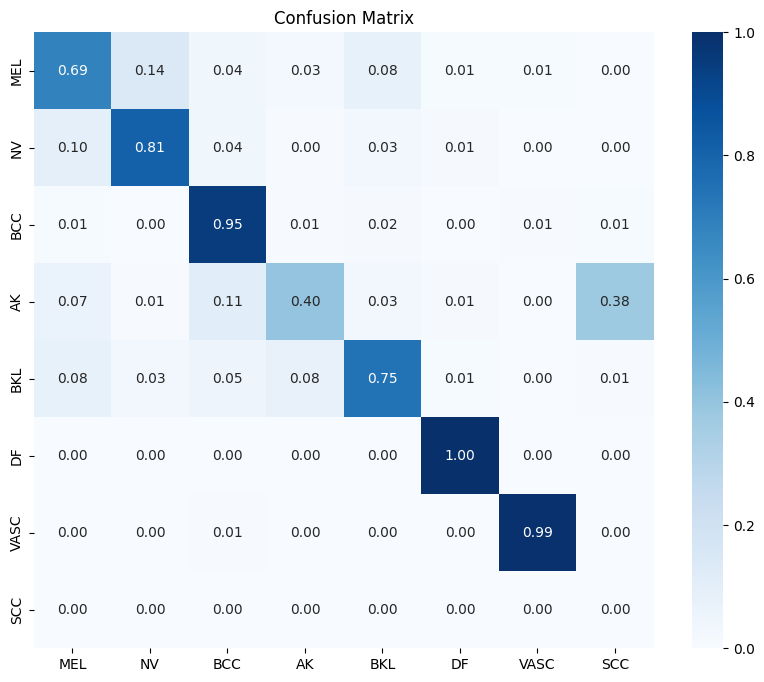

In [27]:
conf_matrix = confusion_matrix(y_true, y_pred, normalize="true")
plt.figure(figsize=(10, 8))
sns.heatmap(conf_matrix, annot=True, cmap="Blues", fmt=".2f",
            xticklabels=LABELS, yticklabels=LABELS)
plt.title("Confusion Matrix")
plt.show()

### ISIC 2019

In [28]:
# ISIC 2019
test_loss, test_accuracy = model.evaluate(test_dataset_2)
print(f"HAM10000 Test Accuracy: {test_accuracy}")
print(f"HAM10000 Test Loss: {test_loss}")

515/515 ━━━━━━━━━━━━━━━━━━━━ 320s 621ms/step - accuracy: 0.6015 - loss: 1.5660
HAM10000 Test Accuracy: 0.49259528517723083
HAM10000 Test Loss: 2.0381863117218018


In [29]:
y2_true = np.concatenate([y for _, y in test_dataset_2], axis=0)
y2_pred = model.predict(test_dataset_2)
y2_pred = np.argmax(y2_pred, axis=1)

2025-03-10 12:23:58.876199: I tensorflow/core/framework/local_rendezvous.cc:405] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence


515/515 ━━━━━━━━━━━━━━━━━━━━ 375s 726ms/step


In [30]:
score_report = classification_report(y2_true, 
                                     y2_pred, 
                                     target_names=[LABELS[i] for i in range(8)])
print(score_report)

              precision    recall  f1-score   support

         MEL       0.63      0.32      0.42      3374
          NV       0.85      0.67      0.75      2495
         BCC       0.39      0.71      0.50       975
          AK       0.18      0.53      0.27       374
         BKL       0.35      0.41      0.38       660
          DF       0.23      0.42      0.30        91
        VASC       0.16      0.48      0.24       104
         SCC       0.15      0.41      0.21       165

    accuracy                           0.49      8238
   macro avg       0.37      0.49      0.38      8238
weighted avg       0.60      0.49      0.51      8238



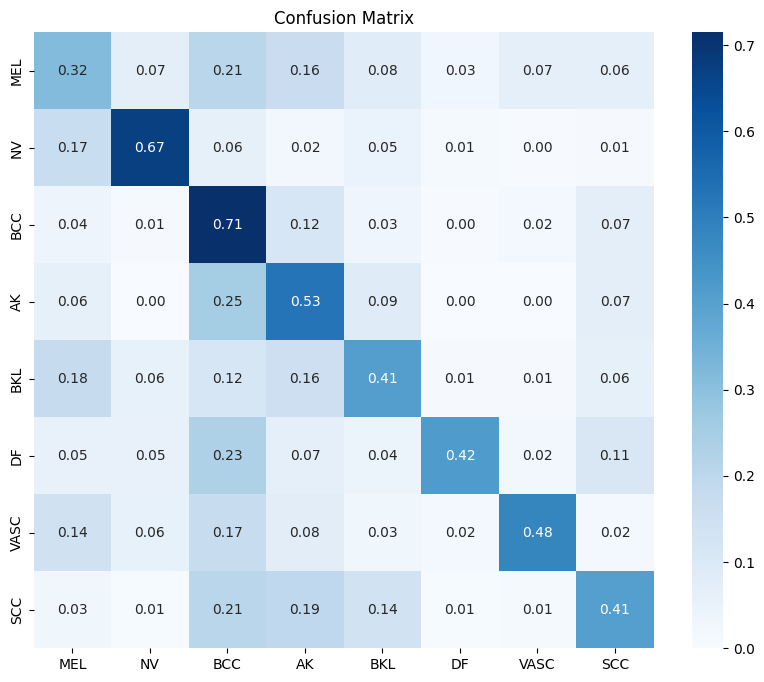

In [31]:
conf_matrix = confusion_matrix(y2_true, 
                               y2_pred, 
                               normalize="true")
plt.figure(figsize=(10, 8))
sns.heatmap(conf_matrix, annot=True, cmap="Blues", fmt=".2f",
            xticklabels=LABELS, yticklabels=LABELS)
plt.title("Confusion Matrix")
plt.show()

In [32]:
import os
import random
import matplotlib.pyplot as plt
import tensorflow as tf
import numpy as np
from tensorflow.keras.preprocessing import image
import pandas as pd

# Define class labels (update according to your dataset)
LABELS = ['akiec', 'bcc', 'bkl', 'df', 'mel', 'nv', 'vasc']

# Load a trained model (update with your model path)
MODEL_PATH = "your_model.h5"
model = tf.keras.models.load_model(MODEL_PATH)

# Function to preprocess image
def preprocess_image(img_path, img_size=(224, 224)):  # Adjust size if needed
    img = image.load_img(img_path, target_size=img_size)
    img_array = image.img_to_array(img) / 255.0  # Normalize to [0,1]
    img_array = np.expand_dims(img_array, axis=0)  # Add batch dimension
    return img_array

# Group the images by their labels
def group_images_by_label(paths, labels):
    grouped = {label: [] for label in LABELS}
    for path, label in zip(paths, labels):
        grouped[LABELS[label]].append(path)
    return grouped

# Get grouped images for each dataset
grouped_test_1 = group_images_by_label(test_paths, test_labels)
grouped_test_2 = group_images_by_label(test_paths_2, test_labels_2)

# Select one image per label from each dataset
selected_images_1 = {label: random.choice(paths) for label, paths in grouped_test_1.items()}
selected_images_2 = {label: random.choice(paths) for label, paths in grouped_test_2.items()}

# Prepare a figure for displaying images
fig, axes = plt.subplots(2, len(LABELS), figsize=(20, 10))

# Make predictions and display images
for idx, label in enumerate(LABELS):
    # Get the selected images
    img_1_path = selected_images_1[label]
    img_2_path = selected_images_2[label]

    # Preprocess and predict for each image
    img_1 = preprocess_image(img_1_path)
    img_2 = preprocess_image(img_2_path)
    
    pred_1 = model.predict(img_1)
    pred_2 = model.predict(img_2)
    
    # Get predicted labels
    label_1 = LABELS[np.argmax(pred_1)]
    label_2 = LABELS[np.argmax(pred_2)]

    # Plot the images with predictions
    axes[0, idx].imshow(image.load_img(img_1_path))
    axes[0, idx].set_title(f"Dataset 1\nPred: {label_1}")
    axes[0, idx].axis('off')
    
    axes[1, idx].imshow(image.load_img(img_2_path))
    axes[1, idx].set_title(f"Dataset 2\nPred: {label_2}")
    axes[1, idx].axis('off')

plt.tight_layout()
plt.show()


FileNotFoundError: [Errno 2] Unable to open file (unable to open file: name = 'your_model.h5', errno = 2, error message = 'No such file or directory', flags = 0, o_flags = 0)

In [ ]:
memory_info = tf.config.experimental.get_memory_info('GPU:0')

print("Memory Usage (Bytes):", memory_info)